# Linear Programming:

Linear "Programming" is not programming in the sense that we know it, but is a subject of operations reseach developed during WW2 for logistics and resource allocation. Linear Programming (LP) is a framework to solve complex decisions through mathematical models. <br>
```Bazaraa, M. S., Jarvis, J. J., & Sherali, H. D. (2010). Linear programming and network flows (4th ed.). John Wiley & Sons.```


## Primary Example:

Suppose you want to maximize the number of resources transported from point A to B. There are multiple resource types:

- R1: 3 units
- R2: 5 units

However, each resource comes with weights that an aircraft has to handle:

- R1: 1k lbs
- R2: 2k lbs

The aircraft has a total capacity of 9k pounds. 

**What resources need to be put on the aircraft to maximize unit transportation?**

This example is simple enough for us to guess at what a solution may be before we do any math. The question is, what math has to be done?

### Example Math:

Since this is a math problem, we'll need to make expressions for everything. Let's say that the total number of units is described by the function: <br><br> $f(x_1, x_2) = 3x_1 + 5x_2 $ <br><br>
where $x_1$ are the number of resources (R1) that will be loaded onto aircraft ($x_2 \Rightarrow$ R2 resources on the plane)


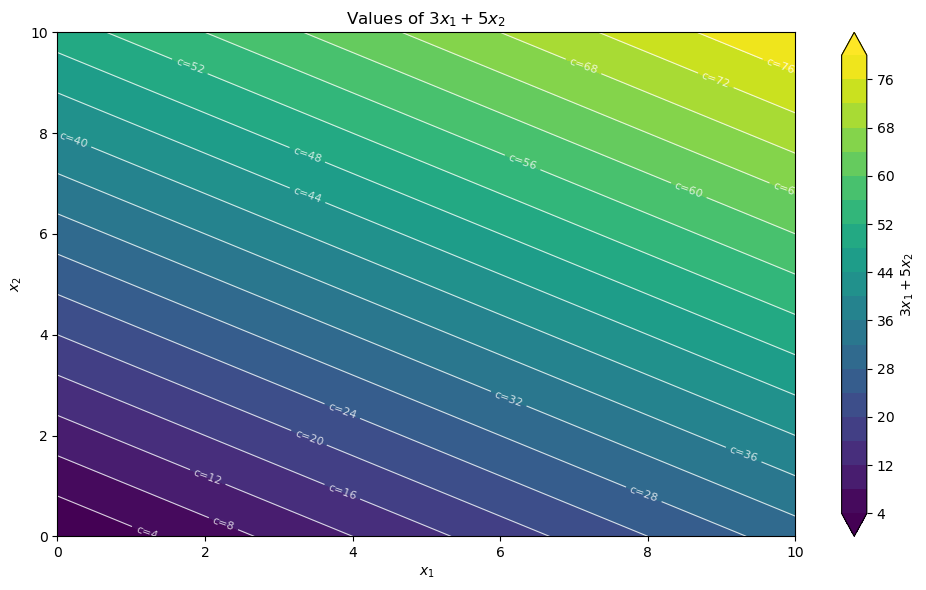

In [1]:
from problems.example1.model import example1
example1.show()

### Unbounded:

If there are no constraints on the problem, then the maximum of $3x_1 + 5x_2$ will be unbounded and $f(x_1, x_2) \rightarrow \infty$. In many real-world problems, optimization has trade-offs. These trade-offs are described through contraints. In this example, the trade-off is the capacity of the aircraft. The aircraft capacity can be described by: <br><br> $x_1 + 2x_2 \leq 9$ (note that units are in 1000lbs, so a final anwser is going to be in 1000s). 

### Full Model:

Maximize $3x_1 + 5x_2$ <br>
Subject to $x_1 + 2x_2 \leq 9$


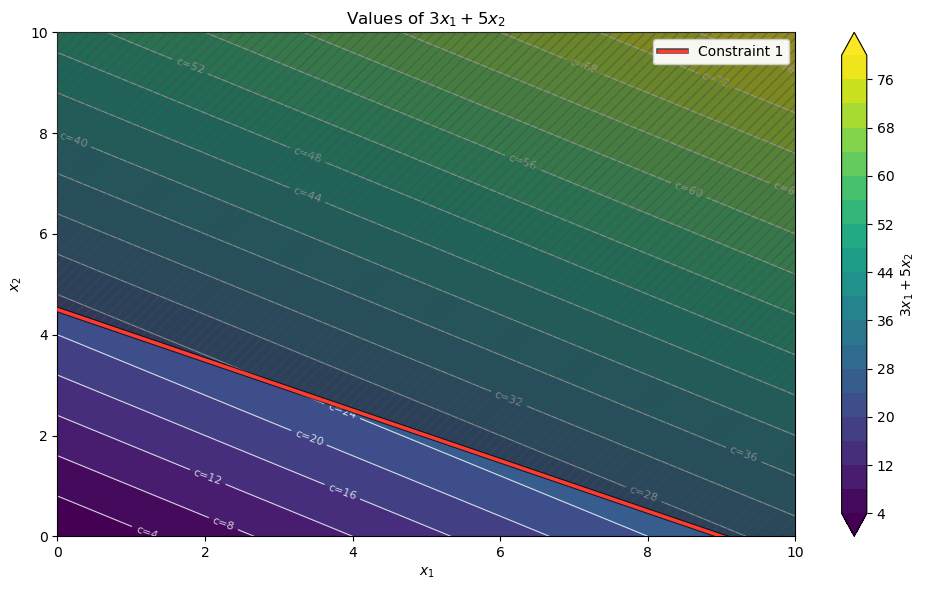

In [2]:
example1.new_plot()
example1.add_constraint(1, 2, 9, label="Constraint 1")
example1.show()

### Solution:
#### My first analytical solution:
The solution that I first when to was a "greedy" approach:

- Maximize the number of R2 loaded onto the aircraft: <br>
$2x_2 \leq 9 \Rightarrow x_2 \leq \frac{9}{2} \Rightarrow x_2 \rightarrow 4$
    - That accounts for 14k lbs 

- Then fill the remaining with R1 <br>
$x_1 \rightarrow 1$

That means my objective function was $f(1, 4) = 3\cdot1 + 5\cdot 4 = 23$

#### Based on the graph, we can do better:

Looking at the shadind, it's clear that R1 is always the better option, and that we should go with that. 

This means that the total best reward we can get is $3\cdot9 + 5\cdot0 = 27$ for $3x_1 + 5x_2$

#### The real question is: How can we get the right anwser every time?
### Example 1 Pyomo Model:

To get required dependencies:
```
conda install -c conda-forge pyomo highspy
OR
pip install pyomo highspy
```

Other solvers:
``` cplex, glpk, cbc``` where glpk is reliable for small problems. <br><br> For the most current high-end open-source solver:
```solver = pyo.SolverFactory("appsi_highs")```



In [2]:
from pyomo import environ as pyo

# Model parameters as dictionaries
rewards = {"resource 1": 3, "resource 2": 5}
weights = {"resource 1": 1, "resource 2": 2}

# Create a Pyomo Model
model = pyo.ConcreteModel()
model.resources = pyo.Set(initialize=list(rewards.keys()))
model.rewards = pyo.Param(model.resources, initialize=rewards)
model.weights = pyo.Param(model.resources, initialize=weights)

# Decision variables: x[r] >= 0 for each resource
model.x = pyo.Var(model.resources, domain=pyo.NonNegativeReals)

# Objective: maximize 3x_1 + 5x_2
model.objective = pyo.Objective(
    expr=sum(model.rewards[r] * model.x[r] for r in model.resources),
    sense=pyo.maximize,
)

# Constraint: 1x_1 + 2x_2 <= 9
def weight_constraint_rule(model):
    return sum(model.weights[r] * model.x[r] for r in model.resources) <= 9
model.weight_constraint = pyo.Constraint(rule=weight_constraint_rule)

# Solve with HiGHS
solver = pyo.SolverFactory("appsi_highs")
results = solver.solve(model)

# Inspect solution
print("Status:", results.solver.termination_condition)
print("Optimal Objective:", pyo.value(model.objective))
for r in model.resources:
    print(f"{r}: {pyo.value(model.x[r])}")

Status: optimal
Optimal Objective: 27.0
resource 1: 9.0
resource 2: 0.0


## Example 2: Transportation

Let's say that a coffee company has:
- $m$ plants 
    - production capacity $a_i$
- $n$ warehouses
    - demand $b_j$
- $c_{ij}$ costs from plant $i$ to warehouse $j$
- x_{ij} is the determination of how much goes from plant $i$ to warehouse $j$

### Goal: Minimize Transportation Costs

Cost for one $ij$: $c_{ij}x_{ij}$ <br>
Costs for all possible pairs: $\displaystyle\sum_{i=1}^m \sum_{j=1}^n c_{ij}x_{ij}$

#### Constraints:

1. Plant capacity: $\displaystyle\sum_{j=1}^n a_ix_{ij}$ for each $i = 1,2,...,m$
2. Warehouse demand: $\displaystyle\sum_{i=1}^m b_jx_{ij}$ for each $j = 1,2,...,n$
3. Non-negativity: $x_{ij} \geq 0 \rightarrow$ No negative amounts of coffee

**Why is $j$ being summed over for plant capacity?:** Because each plant needs to account for every warehouse it could go to. <br>
For warehouse demand, the coffee could come from any plant, so we sum over $i$ for the second constraint.

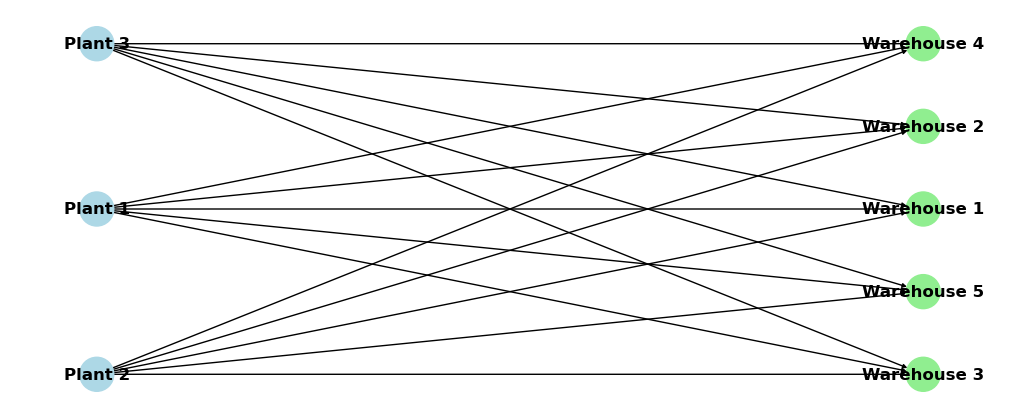

In [38]:
import networkx as nx
import numpy as np
from matplotlib import pyplot as plt


class TransportationProblem:
    def __init__(self, plants=3, warehouses=5, cost_range=(1, 10), capacity_range=(10, 100), demand_range=(10, 100), total_demand=None):
        self.plants = plants
        self.warehouses = warehouses
        self.cost_range = cost_range
        self.capacity_range = capacity_range
        self.demand_range = demand_range
        self.total_demand = np.random.randint(*self.demand_range) if total_demand is None else total_demand
        self.graph = self.create_transportation()
        self.colors = ['lightblue' if self.graph.nodes[n]['type']=='plant' else 'lightgreen' for n in self.graph.nodes()]
        self.pos = nx.bipartite_layout(self.graph, nodes=[n for n in self.graph.nodes() if self.graph.nodes[n]['type']=='plant'])

    def _assign_demand(self):
        return np.random.multinomial(self.total_demand, [1/self.warehouses]*self.warehouses)

    def _assign_capacity(self):
        return np.random.multinomial(self.total_demand, [1/self.plants]*self.plants)

    def create_transportation(self) -> nx.DiGraph:
        G = nx.DiGraph()
        for i in range(self.plants):
            capacity = self._assign_capacity()[i]
            G.add_node(f"Plant {i+1}", type="plant", capacity=capacity)
        for j in range(self.warehouses):
            demand = self._assign_demand()[j]
            G.add_node(f"Warehouse {j+1}", type="warehouse", demand=demand)
        for i in range(self.plants):
            for j in range(self.warehouses):
                cost = np.random.randint(*self.cost_range)
                G.add_edge(f"Plant {i+1}", f"Warehouse {j+1}", cost=cost)
        return G

tp = TransportationProblem()
G = tp.graph
plt.figure(figsize=(10, 4))
nx.draw(G, pos=tp.pos, with_labels=True, node_color=tp.colors, arrowsize=6, node_size=600, font_weight='bold')
plt.show()



In [39]:
print(tp._assign_demand())
print(tp._assign_capacity())


[ 9 10 12  5  4]
[15 14 11]


In [40]:
capacities = {n: G.nodes[n]['capacity'] for n in G.nodes() if G.nodes[n]['type'] == 'plant'}
demands = {n: G.nodes[n]['demand'] for n in G.nodes() if G.nodes[n]['type'] == 'warehouse'}
costs = {(u, v): G.edges[u, v]['cost'] for u, v in G.edges()}

print(f"Costs: {list(costs.keys())[:3]}..., {list(costs.values())}")


Costs: [('Plant 1', 'Warehouse 1'), ('Plant 1', 'Warehouse 2'), ('Plant 1', 'Warehouse 3')]..., [6, 5, 8, 6, 2, 8, 8, 4, 3, 3, 1, 6, 3, 3, 7]


In [ ]:
capacities = {n: G.nodes[n]['capacity'] for n in G.nodes() if G.nodes[n]['type'] == 'plant'}
demands = {n: G.nodes[n]['demand'] for n in G.nodes() if G.nodes[n]['type'] == 'warehouse'}
costs = {(u, v): G.edges[u, v]['cost'] for u, v in G.edges()}


# Create a Pyomo Model
model = pyo.ConcreteModel()
# Define Plant and Warehouse Data
model.plants = pyo.Set(initialize=list(capacities.keys()))
model.warehouses = pyo.Set(initialize=list(demands.keys()))
model.capacities = pyo.Param(model.plants, initialize=capacities)
model.demands = pyo.Param(model.warehouses, initialize=demands)

# Define Cost Data
model.edges = pyo.Set(initialize=list(costs.keys()), dimen=2)
model.costs = pyo.Param(model.edges, initialize=costs)

# Decision variables: x[r] >= 0 for each resource
model.x = pyo.Var(model.edges, domain=pyo.NonNegativeReals)

# Objective: Minimize total transportation cost
model.objective = pyo.Objective(expr=sum(model.costs[e] * model.x[e] for e in model.edges), sense=pyo.minimize)

# Constraint: Capacity constraints for plants
def capacity_constraint_rule(model, p):
    return sum(model.x[e] for e in model.edges if e[0] == p) <= model.capacities[p]
model.capacity_constraint = pyo.Constraint(model.plants, rule=capacity_constraint_rule)

# Constraint: Demand constraints for warehouses
def demand_constraint_rule(model, w):
    return sum(model.x[e] for e in model.edges if e[1] == w) >= model.demands[w]
model.demand_constraint = pyo.Constraint(model.warehouses, rule=demand_constraint_rule)

# Solve with HiGHS
solver = pyo.SolverFactory("appsi_highs")
results = solver.solve(model)

# Inspect solution
print("Status:", results.solver.termination_condition)
print("Optimal Objective:", pyo.value(model.objective))
for e in model.edges:
    print(f"{e}: {pyo.value(model.x[e])}")

Status: optimal
Optimal Objective: 90.0
('Plant 1', 'Warehouse 1'): 0.0
('Plant 1', 'Warehouse 2'): 4.0
('Plant 1', 'Warehouse 3'): 0.0
('Plant 1', 'Warehouse 4'): 0.0
('Plant 1', 'Warehouse 5'): 5.0
('Plant 2', 'Warehouse 1'): 0.0
('Plant 2', 'Warehouse 2'): 0.0
('Plant 2', 'Warehouse 3'): 4.0
('Plant 2', 'Warehouse 4'): 8.0
('Plant 2', 'Warehouse 5'): 0.0
('Plant 3', 'Warehouse 1'): 5.0
('Plant 3', 'Warehouse 2'): 0.0
('Plant 3', 'Warehouse 3'): 5.0
('Plant 3', 'Warehouse 4'): 0.0
('Plant 3', 'Warehouse 5'): 0.0


In [ ]:
from education.problems.transportation.model import TransportationProblem, TransportationLP

tp = TransportationProblem()

lp = TransportationLP(tp)

model, results = lp.solve()

print(results.solver.termination_condition)
print(pyo.value(model.objective))

solution = lp.export_solution(path='problems/transportation_solution.json')

optimal
273.0


In [62]:
list(model.edges)

[('Plant 1', 'Warehouse 1'),
 ('Plant 1', 'Warehouse 2'),
 ('Plant 1', 'Warehouse 3'),
 ('Plant 1', 'Warehouse 4'),
 ('Plant 1', 'Warehouse 5'),
 ('Plant 2', 'Warehouse 1'),
 ('Plant 2', 'Warehouse 2'),
 ('Plant 2', 'Warehouse 3'),
 ('Plant 2', 'Warehouse 4'),
 ('Plant 2', 'Warehouse 5'),
 ('Plant 3', 'Warehouse 1'),
 ('Plant 3', 'Warehouse 2'),
 ('Plant 3', 'Warehouse 3'),
 ('Plant 3', 'Warehouse 4'),
 ('Plant 3', 'Warehouse 5')]

In [67]:
for (i, j) in model.edges:
    print(f"{i, j}: {pyo.value(model.costs[(i, j)])}, {round(pyo.value(model.x[(i, j)]))} ")


('Plant 1', 'Warehouse 1'): 3, 5 
('Plant 1', 'Warehouse 2'): 9, 0 
('Plant 1', 'Warehouse 3'): 9, 0 
('Plant 1', 'Warehouse 4'): 4, 5 
('Plant 1', 'Warehouse 5'): 8, 0 
('Plant 2', 'Warehouse 1'): 1, 0 
('Plant 2', 'Warehouse 2'): 7, 7 
('Plant 2', 'Warehouse 3'): 7, 0 
('Plant 2', 'Warehouse 4'): 3, 0 
('Plant 2', 'Warehouse 5'): 4, 4 
('Plant 3', 'Warehouse 1'): 5, 0 
('Plant 3', 'Warehouse 2'): 3, 1 
('Plant 3', 'Warehouse 3'): 3, 6 
('Plant 3', 'Warehouse 4'): 3, 0 
('Plant 3', 'Warehouse 5'): 7, 0 
